In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = '/content/drive/MyDrive/Project73-Dag/Dogtvt'

for split in ['train', 'valid', 'test']:
    path = os.path.join(base_path, split)
    if os.path.exists(path):
        count = sum([len(files) for r, d, files in os.walk(path)])
        print(f" {split}: {count} images")

 train: 8330 images
 valid: 2380 images
 test: 1190 images


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator as IDG

train_datagen = IDG(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

test_datagen = IDG(rescale=1./255)

gen_args = dict(target_size=(224, 224), batch_size=32, class_mode='categorical')

train_gen = train_datagen.flow_from_directory(f'{base_path}/train', shuffle=True, **gen_args)
valid_gen = test_datagen.flow_from_directory(f'{base_path}/valid', shuffle=False, **gen_args)
test_gen = test_datagen.flow_from_directory(f'{base_path}/test', shuffle=False, **gen_args)

print("เตรียม Data Generators สำเร็จ!")

Found 8330 images belonging to 119 classes.
Found 2380 images belonging to 119 classes.
Found 1190 images belonging to 119 classes.
เตรียม Data Generators สำเร็จ!


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(
    rescale=1.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1.0)

In [ ]:
train_path = '/content/drive/MyDrive/Project73-Dag/Dogtvt/train'
valid_path = '/content/drive/MyDrive/Project73-Dag/Dogtvt/valid'

train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

valid_gen = test_datagen.flow_from_directory(
    valid_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

Found 8330 images belonging to 119 classes.
Found 2380 images belonging to 119 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.applications import EfficientNetB3

base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(119, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print()

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau

checkpoint = ModelCheckpoint('best_dog_model_B3.keras', save_best_only=True, monitor='val_accuracy', mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7)

print("เริ่มการเทรน Phase 1")

history = model.fit(
    train_gen,
    epochs=5,
    validation_data=valid_gen,
    callbacks=[checkpoint, reduce_lr]
)

เริ่มการเทรน Phase 1


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 6299s 24s/step - accuracy: 0.5182 - loss: 2.2554 - val_accuracy: 0.8441 - val_loss: 0.5197 - learning_rate: 0.0010
Epoch 2/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 1693s 6s/step - accuracy: 0.7753 - loss: 0.8351 - val_accuracy: 0.8462 - val_loss: 0.6136 - learning_rate: 0.0010
Epoch 3/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 1682s 6s/step - accuracy: 0.8194 - loss: 0.6761 - val_accuracy: 0.8546 - val_loss: 0.5991 - learning_rate: 0.0010
Epoch 4/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 1701s 7s/step - accuracy: 0.8499 - loss: 0.5382 - val_accuracy: 0.8727 - val_loss: 0.5043 - learning_rate: 2.0000e-04
Epoch 5/5
261/261 ━━━━━━━━━━━━━━━━━━━━ 1682s 6s/step - accuracy: 0.8728 - loss: 0.4245 - val_accuracy: 0.8727 - val_loss: 0.4894 - learning_rate: 2.0000e-04


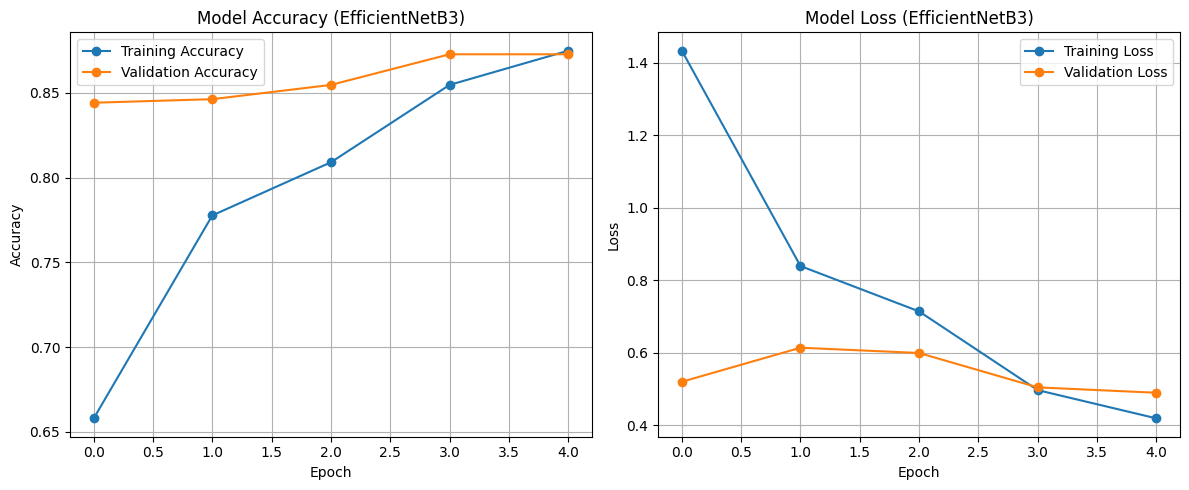

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy (EfficientNetB3)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Model Loss (EfficientNetB3)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
final_train_acc = history.history['accuracy'][-1] * 100
final_val_acc = history.history['val_accuracy'][-1] * 100
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

print("สรุปผลประสิทธิภาพโมเดล EfficientNetB3")
print(f"ความแม่นยำบนชุดข้อมูลฝึกฝน (Train Accuracy): {final_train_acc:.2f}%")
print(f"ความแม่นยำบนชุดข้อมูลตรวจสอบ (Validation Accuracy): {final_val_acc:.2f}%")
print(f"ค่าความผิดพลาดบนชุดข้อมูลฝึกฝน (Train Loss): {final_train_loss:.4f}")
print(f"ค่าความผิดพลาดบนชุดข้อมูลตรวจสอบ (Validation Loss): {final_val_loss:.4f}")

สรุปผลประสิทธิภาพโมเดล EfficientNetB3
ความแม่นยำบนชุดข้อมูลฝึกฝน (Train Accuracy): 87.48%
ความแม่นยำบนชุดข้อมูลตรวจสอบ (Validation Accuracy): 87.27%
ค่าความผิดพลาดบนชุดข้อมูลฝึกฝน (Train Loss): 0.4189
ค่าความผิดพลาดบนชุดข้อมูลตรวจสอบ (Validation Loss): 0.4894


In [ ]:
import os

save_path = '/content/drive/MyDrive/Project73-Dag'

if not os.path.exists(save_path):
    os.makedirs(save_path)

model_name = 'EfficientNetB3_Model.keras'
full_save_path = os.path.join(save_path, model_name)

model.save(full_save_path)
print(f"เซฟโมเดลเรียบร้อยแล้ว: {full_save_path}")

เซฟโมเดลเรียบร้อยแล้ว: /content/drive/MyDrive/Project73-Dag/EfficientNetB3_Model.keras


In [ ]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

model_path = '/content/drive/MyDrive/Project73-Dag/EfficientNetB3_Model.keras'
loaded_model = load_model(model_path)

class_labels = list(train_gen.class_indices.keys())

print(f"โหลดโมเดลสำเร็จ {len(class_labels)} สายพันธุ์")

โหลดโมเดลสำเร็จ 119 สายพันธุ์


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step


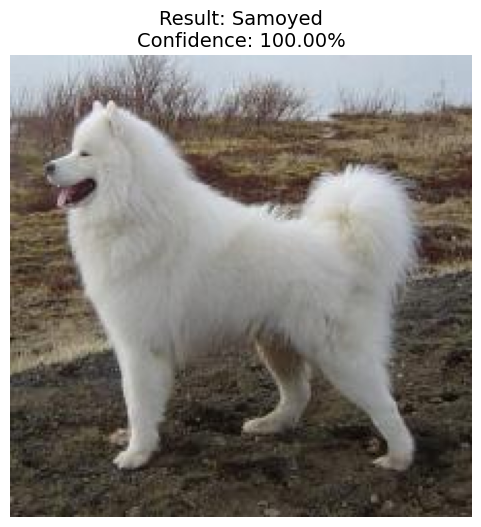

In [ ]:
def predict_and_show(img_path):

    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = loaded_model.predict(img_array)
    score = np.max(predictions)
    class_idx = np.argmax(predictions)
    predicted_label = class_labels[class_idx]

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Result: {predicted_label}\nConfidence: {score*100:.2f}%",
              fontsize=14, color='black' if score > 0.5 else 'red')
    plt.axis('off')
    plt.show()

test_img = '/content/drive/MyDrive/Project73-Dag/Dogtvt/test/Samoyed/n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg'
predict_and_show(test_img)